In [2]:
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

In [3]:
data = pd.read_csv('Dataset.csv')
data.head()

,Type,url_length,number_of_dots_in_url,having_repeated_digits_in_url,number_of_digits_in_url,number_of_special_char_in_url,number_of_hyphens_in_url,number_of_underline_in_url,number_of_slash_in_url,number_of_questionmark_in_url,...,having_digits_in_subdomain,number_of_digits_in_subdomain,having_repeated_digits_in_subdomain,having_path,path_length,having_query,having_fragment,having_anchor,entropy_of_url,entropy_of_domain
0,0,37,2,0,0,8,0,0,5,0,...,0,0,1,0,3,0,0,0,4.010412,2.751629
1,1,70,5,0,0,12,0,0,6,0,...,0,0,1,0,4,0,0,0,4.089470,3.532573
2,0,42,2,0,6,8,0,0,3,1,...,0,0,1,0,1,1,0,0,4.386016,3.344698
3,0,46,2,0,0,7,0,0,4,0,...,0,0,1,0,2,0,0,0,4.221947,3.189898
4,0,51,3,0,0,9,0,0,5,0,...,0,0,1,0,3,0,0,0,4.103538,2.952820


In [4]:
data.duplicated().sum()

np.int64(118172)

In [5]:
clean_data= data.drop_duplicates()
clean_data.duplicated().sum()

np.int64(0)

In [6]:
X = clean_data.drop('Type', axis=1)
y = clean_data['Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
classifiers = {
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=42),
    # 'Logistic Regression': LogisticRegression(max_it/er=200, random_state=42),
    # 'SVM': SVC(),
    # 'KNN': KNeighborsClassifier(),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42) 
}

In [20]:
param_grids = {
    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20]
    },
    'Gradient Boosting': { 
        'max_iter': [100, 200],  
        'learning_rate': [0.01, 0.1, 1]
    },
    # 'Logistic Regression': {
    #     'C': [0.1, 1, 10]
    # },
    # 'SVM': {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
    # 'KNN': {'n_neighbors': [3, 5, 7, 9], 'p': [1, 2]},
    'XGBoost': {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 1],
        'max_depth': [3, 6, 9]
    }
}

In [21]:
print("\nMemulai Hyperparameter Tuning...\n")
hasil_tuning = []
model_terbaik_tersimpan = {}

for name, clf in classifiers.items():
    print(f"Melakukan tuning untuk: {name} ...")
    start_time = time.time()
    
    grid_search = GridSearchCV(
        estimator=clf,
        param_grid=param_grids[name],
        cv=3,                     
        scoring='accuracy',
        n_jobs=-1                    
    )
    
    grid_search.fit(X_train_scaled, y_train)
    
    best_model = grid_search.best_estimator_
    model_terbaik_tersimpan[name] = best_model
    
    y_pred = best_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    
    end_time = time.time()
    f1 = f1_score(y_test, y_pred, average='weighted')
    waktu = end_time - start_time

    print(f"Model: {name}")
    print(f"Accuracy: {acc:.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    hasil_tuning.append({
        'Model': name,
        'Best Parameter': str(grid_search.best_params_),
        'Akurasi Test (%)': round(acc * 100, 2),
        'Total Waktu Tuning (Detik)': round(waktu, 2)
    })


Memulai Hyperparameter Tuning...

Melakukan tuning untuk: Random Forest ...
Model: Random Forest
Accuracy: 0.9029
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91     13351
           1       0.92      0.88      0.90     12605

    accuracy                           0.90     25956
   macro avg       0.90      0.90      0.90     25956
weighted avg       0.90      0.90      0.90     25956

Melakukan tuning untuk: Gradient Boosting ...
Model: Gradient Boosting
Accuracy: 0.8952
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90     13351
           1       0.92      0.86      0.89     12605

    accuracy                           0.90     25956
   macro avg       0.90      0.89      0.89     25956
weighted avg       0.90      0.90      0.90     25956

Melakukan tuning untuk: XGBoost ...
Model: XGBoost
Accuracy: 0.9041
Classification Report:
      

In [ ]:
# hasil_evaluasi = []

In [ ]:
# for name, clf in classifiers.items():
#     print(f"   -> Sedang melatih: {name} ...")
#     start_time = time.time()
    
#     clf.fit(X_train_scaled, y_train) 
#     y_pred = clf.predict(X_test_scaled) 
    
#     end_time = time.time()
    
#     acc = accuracy_score(y_test, y_pred)
#     f1 = f1_score(y_test, y_pred)
#     waktu = end_time - start_time

#     print(f"Model: {name}")
#     print(f"Accuracy: {acc:.4f}")
#     print("Classification Report:")
#     print(classification_report(y_test, y_pred))
    
#     hasil_evaluasi.append({
#         'Model': name,
#         'Accuracy (%)': round(acc * 100, 2),
#         'F1-Score (%)': round(f1 * 100, 2),
#         'Waktu Training (Detik)': round(waktu, 2)
#     })

In [23]:
df_hasil = pd.DataFrame(hasil_tuning).sort_values(by='Akurasi Test (%)', ascending=False).reset_index(drop=True)
print("\n=== PERBANDINGAN MODEL ===")
try:
    display(df_hasil)
except:
    print(df_hasil.to_string())


=== PERBANDINGAN MODEL ===


,Model,Best Parameter,Akurasi Test (%),Total Waktu Tuning (Detik)
0,XGBoost,"{'learning_rate': 0.1, 'max_depth': 9, 'n_esti...",90.41,22.23
1,Random Forest,"{'max_depth': None, 'n_estimators': 200}",90.29,56.72
2,Gradient Boosting,"{'learning_rate': 0.1, 'max_iter': 200}",89.52,13.95


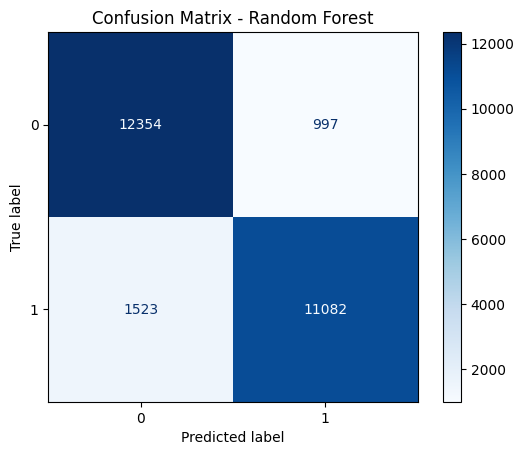

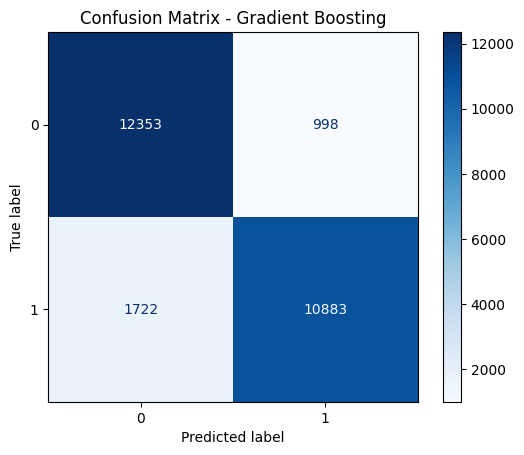

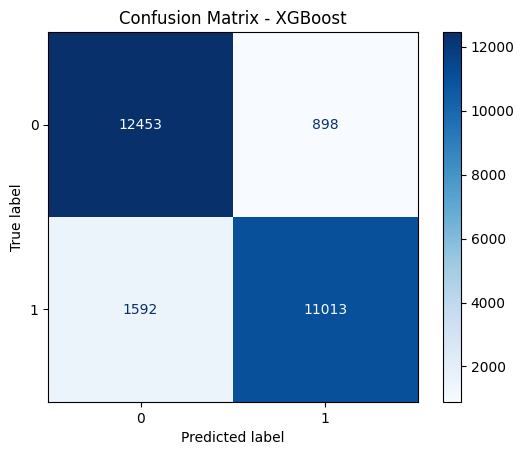

In [25]:
# conffusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, clf in model_terbaik_tersimpan.items():
    y_pred = clf.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f'Confusion Matrix - {name}')
    plt.show()